# Exploratory Data Analysis (EDA): Data Pengguna Portal Bisnis.id (`bisnis_id_prod.User`)

- **Mata Kuliah:** Data Science (`PSIKS2W002`) — Tugas UTS
- **Sumber Data:** Database MariaDB (`mariadb-dev`), DB `bisnis_id_prod`, Tabel `User`
- **Ukuran Data:** Populasi penuh 762.792 baris (48 kolom) | Sampel terstratifikasi bersih: **15.003 baris (22 kolom)**
- **Catatan Penting:** Kolom lama `is_retained_user` **tidak digunakan** karena sudah tidak aktif di sistem. Sebagai gantinya, analisis difokuskan pada **kelengkapan profil demografis (`has_demografi` & `profile_completeness_pct`)** dan **segmentasi kanal akuisisi (`auth_channel`)**.

---

## Bab 1: Pendahuluan & Memahami Masalah (*Understanding the Problem*)

### 1.1 Latar Belakang Masalah & Tujuan Utama
Portal berita Bisnis.id menggunakan sistem akun terpusat pada tabel `User` (762.792 akun terdaftar hingga November 2026). Sebagian besar pengguna mendaftar dengan cepat menggunakan *Single Sign-On* (Google SSO), sehingga informasi demografis (jenis kelamin, tanggal lahir, pendidikan, penghasilan) banyak yang kosong. Selain itu, data historis sejak tahun 2012 menyimpan sejumlah anomali seperti tanggal kosong `'0000-00-00'` dan penulisan kategori yang tidak seragam.

**Tujuan utama analisis ini:**
1. Memeriksa kualitas dan kelengkapan data pengguna pada tabel `User`.
2. Mengidentifikasi pola penyebab kekosongan data demografis dan cara menanganinya.
3. Menganalisis karakteristik pengguna berdasarkan jalur pendaftaran (`auth_channel`), umur akun (`account_age_days`), dan kelengkapan profil (`has_demografi` & `profile_completeness_pct`).

### 1.2 Tipe Masalah
Analisis ini mengarah pada dua tipe masalah konseptual (*tanpa implementasi ML pada tahap UTS*):
1. **Klasifikasi Biner:** Memprediksi apakah pengguna melengkapi data demografis (`has_demografi`: `1` = terisi minimal satu kolom demografi, `0` = kosong semua).
2. **Klasterisasi:** Mengelompokkan segmen pengguna berdasarkan kanal pendaftaran, umur akun, dan tingkat kelengkapan profil.

### 1.3 Metrik Keberhasilan
- **Klasifikasi (`has_demografi`):** Menggunakan **F1-Score** (bukan akurasi biasa) karena proporsi kelas sangat tidak seimbang (>93% kosong vs <7% terisi).
- **Klasterisasi:** Menggunakan **Silhouette Score** untuk mengukur seberapa jelas pemisahan antar kelompok pengguna.

## Bab 2: Memahami Data (*Understanding the Data*)

### 2.1 Pengumpulan Data (*Data Collection*)
- **Sumber Data:** Database internal `bisnis_id_prod` tabel `User` di container Docker `mariadb-dev` (MariaDB 11.4).
- **Ekstraksi & Privasi (UU PDP):** Data ditarik melalui query SQL dengan **masking PII** (kolom sensitif seperti email utuh, password hash, nomor telepon, dan alamat tidak disimpan; hanya panjang karakter `fullname_len`, `username_len`, serta kolom non-PII yang diekstrak ke sampel terstratifikasi 15.003 baris).

Contoh skrip ekstraksi SQL yang aman (tanpa hardcoded password):
```python
import os, subprocess, pandas as pd

# Mengambil kredensial dari environment variable
db_pass = os.environ.get("MARIADB_PASSWORD")
query = """
SELECT Id, Active, user_type, is_migration, is_merged,
       CASE WHEN google_id IS NOT NULL AND google_id != '' THEN 'Google SSO'
            WHEN apple_id IS NOT NULL AND apple_id != '' THEN 'Apple ID'
            WHEN fb_id IS NOT NULL AND fb_id != '' THEN 'Facebook OAuth'
            ELSE 'Direct Email / Legacy' END AS auth_channel,
       Registerdate, birth_date, gender, education, outcome
FROM User;
"""
```

### 2.2 Deskripsi & Eksplorasi Awal Data
- **Populasi penuh di DB:** 762.792 baris dan 48 kolom (pendaftaran 2012–2026).
- **Sampel bersih untuk EDA:** 15.003 baris dan 22 kolom (tanpa `is_retained_user` dan tanpa PII).

### 2.3 Ringkasan Kualitas Data (Audit Awal dari Populasi)
- **Missing & Zero-Date:** Banyak tanggal kosong disimpan sebagai `'0000-00-00'` (misal `Registerdate` 5.100 baris, `birth_date` 106.012 baris) selain `NULL`.
- **Duplikat & Soft-Delete:** `Id` unik (0 duplikat), namun ditemukan 788 akun dengan email berakhiran `_deleted`.
- **Outliers Usia:** Ditemukan usia ekstrem mulai dari 0,08 tahun (tahun lahir 2026) hingga 107 tahun (tahun lahir 1919).
- **Inkonsistensi & Anomali:** Kolom `gender` berisi `'0'` (107 baris), kolom `outcome` mengandung HTML entity `&gt;`/`&lt;` (2.513 baris) dan 4 baris payload SQL Injection, serta kolom `referer` memiliki karakter rusak.

### 2.4 Eksplorasi Visual Awal & 2.5 Penyelarasan Bisnis
Tahap berikut memuat sampel bersih dan menampilkan grafik tren pendaftaran tahunan serta proporsi jalur pendaftaran (`auth_channel`).

Populasi DB : 762.792 baris x 48 kolom
Sampel EDA  : 15,003 baris x 22 kolom


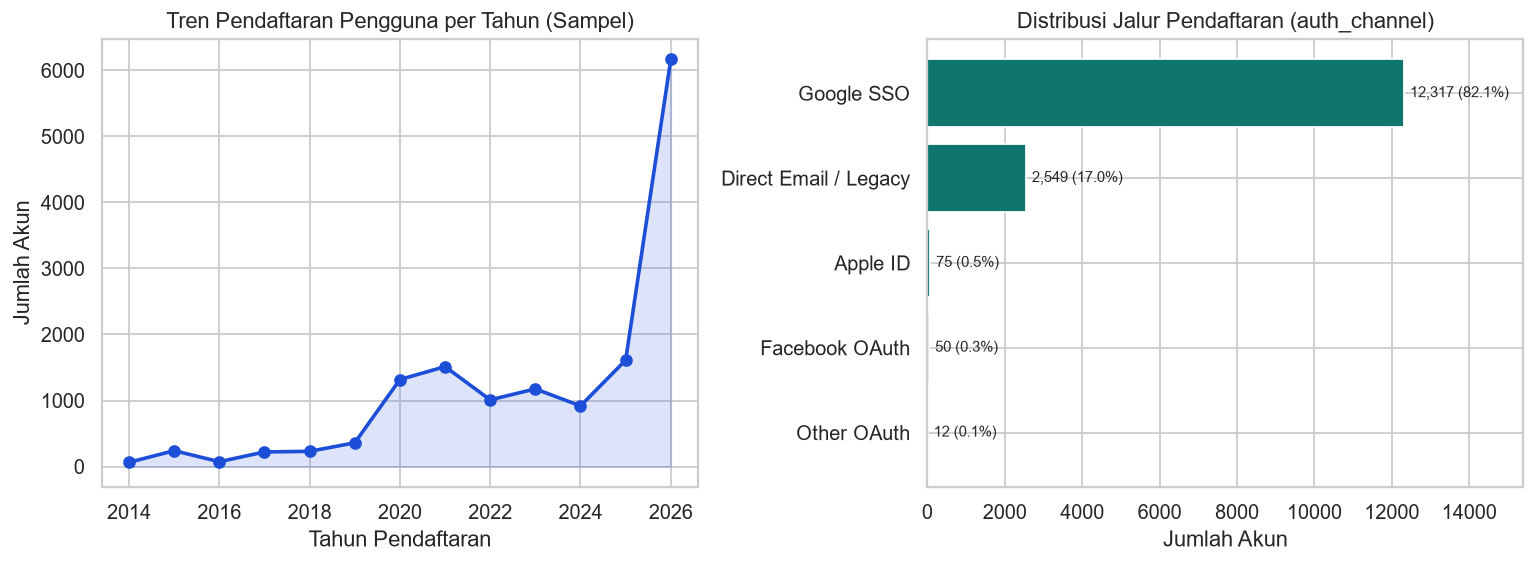

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 150
os.makedirs("figures", exist_ok=True)

df_raw = pd.read_csv("data/users_bisnisid_sample.csv")
print(f"Populasi DB : 762.792 baris x 48 kolom")
print(f"Sampel EDA  : {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Tren pendaftaran per tahun
reg_counts = df_raw["reg_year"].dropna().astype(int).value_counts().sort_index()
axes[0].plot(reg_counts.index, reg_counts.values, marker="o", color="#1d4ed8", linewidth=2)
axes[0].fill_between(reg_counts.index, reg_counts.values, alpha=0.15, color="#1d4ed8")
axes[0].set_title("Tren Pendaftaran Pengguna per Tahun (Sampel)")
axes[0].set_xlabel("Tahun Pendaftaran")
axes[0].set_ylabel("Jumlah Akun")

# 2. Proporsi auth_channel
chan_counts = df_raw["auth_channel"].value_counts()
bars = axes[1].barh(chan_counts.index[::-1], chan_counts.values[::-1], color="#0f766e")
axes[1].set_title("Distribusi Jalur Pendaftaran (auth_channel)")
axes[1].set_xlabel("Jumlah Akun")
for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 150, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({w/len(df_raw)*100:.1f}%)", va="center", fontsize=8.5)
axes[1].set_xlim(0, chan_counts.max() * 1.25)

plt.tight_layout()
plt.savefig("figures/fig1_tren_dan_kanal.png", dpi=160, bbox_inches="tight")
plt.show()

## Bab 3: Memuat & Memeriksa Data (*Importing and Inspecting the Data*)

### 3.1 Import Library dan Loading Dataset
Analisis ini menggunakan `pandas`, `numpy`, `scipy`, `matplotlib`, `seaborn`, dan `scikit-learn` (`StandardScaler`, `MinMaxScaler`). Dataset dimuat dari `data/users_bisnisid_sample.csv`.

### 3.2 Inspeksi Dimensi dan Struktur Data (`head`, `shape`, `columns`)
### 3.3 Pemeriksaan Tipe Data dan Informasi Umum (`info`)
### 3.4 Ringkasan Statistik Awal (`describe`)

In [2]:
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler

df = pd.read_csv("data/users_bisnisid_sample.csv")

print("=== 3.2 Dimensi & Nama Kolom ===")
print("Shape:", df.shape)
print("Columns:", list(df.columns))
display_head = df.head(5)
print("\n5 Baris Pertama:")
print(display_head[["Id", "Active", "auth_channel", "reg_year", "account_age_days", "age_years_raw", "gender_clean", "profile_completeness_pct"]].to_string(index=False))

print("\n=== 3.3 Informasi Tipe Data (df.info) ===")
df.info()

print("\n=== 3.4 Ringkasan Statistik Awal (Numerik) ===")
num_cols_preview = ["account_age_days", "age_years_raw", "profile_completeness_pct", "fullname_len", "username_len"]
print(df[num_cols_preview].describe().round(2).to_string())

print("\n=== 3.4 Ringkasan Statistik Awal (Kategorikal) ===")
cat_cols_preview = ["auth_channel", "referer_group", "gender_clean", "education", "outcome_clean"]
print(df[cat_cols_preview].describe(include="all").to_string())

=== 3.2 Dimensi & Nama Kolom ===
Shape: (15003, 22)
Columns: ['Id', 'Active', 'user_type', 'is_migration', 'is_merged', 'auth_channel', 'referer_group', 'reg_year', 'reg_month', 'reg_hour', 'is_weekend_reg', 'account_age_days', 'age_years_raw', 'gender_clean', 'education', 'outcome_clean', 'profile_fields_filled', 'profile_completeness_pct', 'fullname_len', 'username_len', 'sso_channel_count', 'login_recency_days']

5 Baris Pertama:
    Id  Active auth_channel  reg_year  account_age_days  age_years_raw gender_clean  profile_completeness_pct
111440       1   Google SSO    2020.0       2191.818090            NaN          NaN                  9.090909
 63501       1   Google SSO    2019.0       2504.362164            NaN          NaN                  9.090909
496244       1   Google SSO    2026.0        281.140000            NaN          NaN                  9.090909
 85272       1   Google SSO    2020.0       2342.619780            NaN          NaN                  9.090909
166650       

## Bab 4: Penanganan Data yang Hilang (*Handling Missing Data*)

### 4.1 Identifikasi dan Visualisasi Nilai yang Hilang
Jumlah dan persentase `NaN` pada setiap kolom dihitung lalu divisualisasikan dengan bar chart.

### 4.2 Analisis Mekanisme Missing Data
Untuk menguji apakah data kosong bersifat **MAR (*Missing at Random*)**, persentase pengisian `gender_clean` dibandingkan antara pengguna **Google SSO** dan **Direct Email / Legacy**. Jika persentasenya berbeda jauh, artinya kekosongan data dipengaruhi oleh jalur pendaftaran (MAR).

### 4.3 Strategi Eliminasi (*Deletions*)
1. **Hapus kolom `login_recency_days`:** Kosong **>98%** karena pencatatan sesi lama sudah tidak dipakai di sistem terbaru. *(Kolom `is_retained_user` juga sudah dikecualikan sejak awal).*
2. **Hapus 101 baris dengan `reg_year` / `account_age_days` kosong:** Jumlahnya sangat kecil (**0,67%**) akibat `'0000-00-00'` di database, sehingga aman dihapus tanpa merusak pola data.

### 4.4 Strategi Imputasi (*Imputation Methods*)
- **Numerik (`age_years_raw`):** Karena distribusinya miring dan memiliki outlier, digunakan **Median** pada kolom salinan `age_imputed_median` (hanya untuk demonstrasi; pada analisis demografi murni nilai kosong tetap dibiarkan agar tidak menciptakan bias).
- **Kategorikal (`gender_clean`, `education`, `outcome_clean`):** Kekosongan >93% berarti pengguna memang belum mengisi profil, sehingga paling tepat diisi kategori baru **`"Tidak Diisi"`** (bukan Modus, agar tidak memalsukan mayoritas demografi).

=== 4.1 Tabel Kolom dengan Missing Values ===
                    Missing_Count  Missing_Pct
outcome_clean               14860        99.05
education                   14817        98.76
login_recency_days          14765        98.41
age_years_raw               14714        98.07
gender_clean                14024        93.47
reg_year                      101         0.67
reg_month                     101         0.67
account_age_days              101         0.67
reg_hour                      101         0.67
is_weekend_reg                101         0.67

=== 4.2 Bukti Mekanisme MAR (Keterisian Gender per Kanal) ===
auth_channel
Apple ID                   2.67
Direct Email / Legacy     29.58
Facebook OAuth            26.00
Google SSO                 1.61
Other OAuth              100.00

=== 4.3 Eliminasi ===
Kolom 'login_recency_days' dihapus (missing > 98%).
Baris sebelum dropna(reg_year): 15,003 -> Sesudah: 14,902 (dihapus 101 baris = 0.67%).

=== 4.4 Imputasi ===
Median age_years_

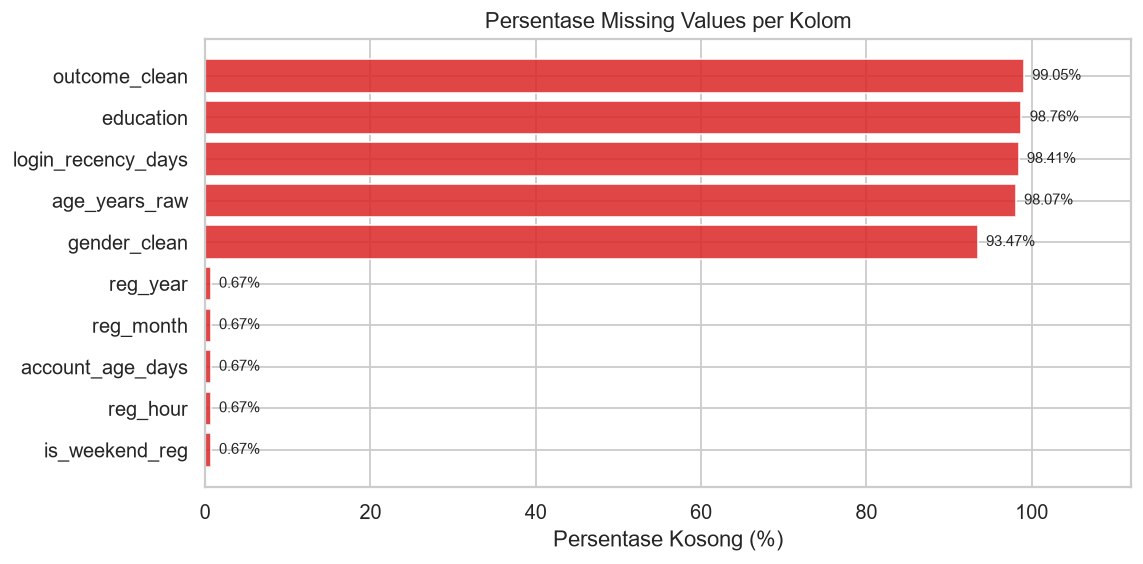

In [3]:
# 4.1 Hitung Missing Values
miss_cnt = df.isnull().sum()
miss_pct = (miss_cnt / len(df) * 100).round(2)
miss_df = pd.DataFrame({"Missing_Count": miss_cnt, "Missing_Pct": miss_pct})
miss_df = miss_df[miss_df["Missing_Count"] > 0].sort_values("Missing_Pct", ascending=False)
print("=== 4.1 Tabel Kolom dengan Missing Values ===")
print(miss_df.to_string())

# Visualisasi Missing Values
plt.figure(figsize=(9, 4.5))
bars = plt.barh(miss_df.index[::-1], miss_df["Missing_Pct"][::-1], color="#dc2626", alpha=0.85)
plt.title("Persentase Missing Values per Kolom")
plt.xlabel("Persentase Kosong (%)")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va="center", fontsize=8.5)
plt.xlim(0, 112)
plt.tight_layout()
plt.savefig("figures/fig2_missing_values.png", dpi=160, bbox_inches="tight")
plt.show()

# 4.2 Analisis MAR: Bandingkan keterisian gender_clean per auth_channel
print("\n=== 4.2 Bukti Mekanisme MAR (Keterisian Gender per Kanal) ===")
mar_check = df.groupby("auth_channel")["gender_clean"].apply(lambda s: s.notna().mean() * 100).round(2)
print(mar_check.to_string())

# 4.3 Strategi Eliminasi
df_clean = df.drop(columns=["login_recency_days"]).copy()
before_rows = len(df_clean)
df_clean = df_clean.dropna(subset=["reg_year", "account_age_days"]).reset_index(drop=True)
after_rows = len(df_clean)
print(f"\n=== 4.3 Eliminasi ===")
print(f"Kolom 'login_recency_days' dihapus (missing > 98%).")
print(f"Baris sebelum dropna(reg_year): {before_rows:,} -> Sesudah: {after_rows:,} (dihapus {before_rows - after_rows} baris = {(before_rows-after_rows)/before_rows*100:.2f}%).")

# 4.4 Strategi Imputasi
age_median = df_clean["age_years_raw"].median()
df_clean["age_imputed_median"] = df_clean["age_years_raw"].fillna(age_median)
for col in ["gender_clean", "education", "outcome_clean"]:
    df_clean[f"{col}_filled"] = df_clean[col].fillna("Tidak Diisi")

print(f"\n=== 4.4 Imputasi ===")
print(f"Median age_years_raw = {age_median:.2f} tahun (digunakan pada age_imputed_median).")
print("Kolom kategorikal demografi diisi kategori 'Tidak Diisi' pada kolom *_filled.")

## Bab 5: Eksplorasi Karakteristik Data (*Exploring Data Characteristics*)

### 5.1 Analisis Statistik Deskriptif untuk Data Numerik
Menampilkan Mean, Median, Modus, Standar Deviasi, Varians, Min, Q1, Q2, Q3, dan Max untuk variabel numerik utama (`account_age_days`, `profile_completeness_pct`, `age_years_raw`, `fullname_len`).

### 5.2 Analisis Bentuk Distribusi Data (*Skewness* dan *Kurtosis*)
- **Skewness:** Mengukur kemiringan kurva (`> 0` miring kanan / *positif skew*, `< 0` miring kiri, `≈ 0` simetris).
- **Kurtosis (excess):** Mengukur keruncingan ekor (`> 0` leptokurtik/runcing, `< 0` platikurtik/datar, `≈ 0` mesokurtik/normal).

=== 5.1 & 5.2 Statistik Deskriptif, Skewness, dan Kurtosis ===
                Variabel  Count    Mean  Median (Q2)   Modus     Std    Varians   Min     Q1      Q3     Max  Skewness  Kurtosis
        account_age_days  14902 1047.02       482.51 3469.84 1031.05 1063074.03  0.91 208.72 1884.61 4584.36     1.052     0.432
profile_completeness_pct  14902   10.75         9.09    9.09    9.77      95.43  0.00   9.09    9.09  100.00     7.434    58.922
           age_years_raw    286   42.57        40.93   27.51   11.87     140.88 16.69  33.20   51.04   77.32     0.401    -0.394
            fullname_len  14902   12.84        12.00   13.00    4.65      21.64  0.00  10.00   15.00   51.00     0.947     4.158


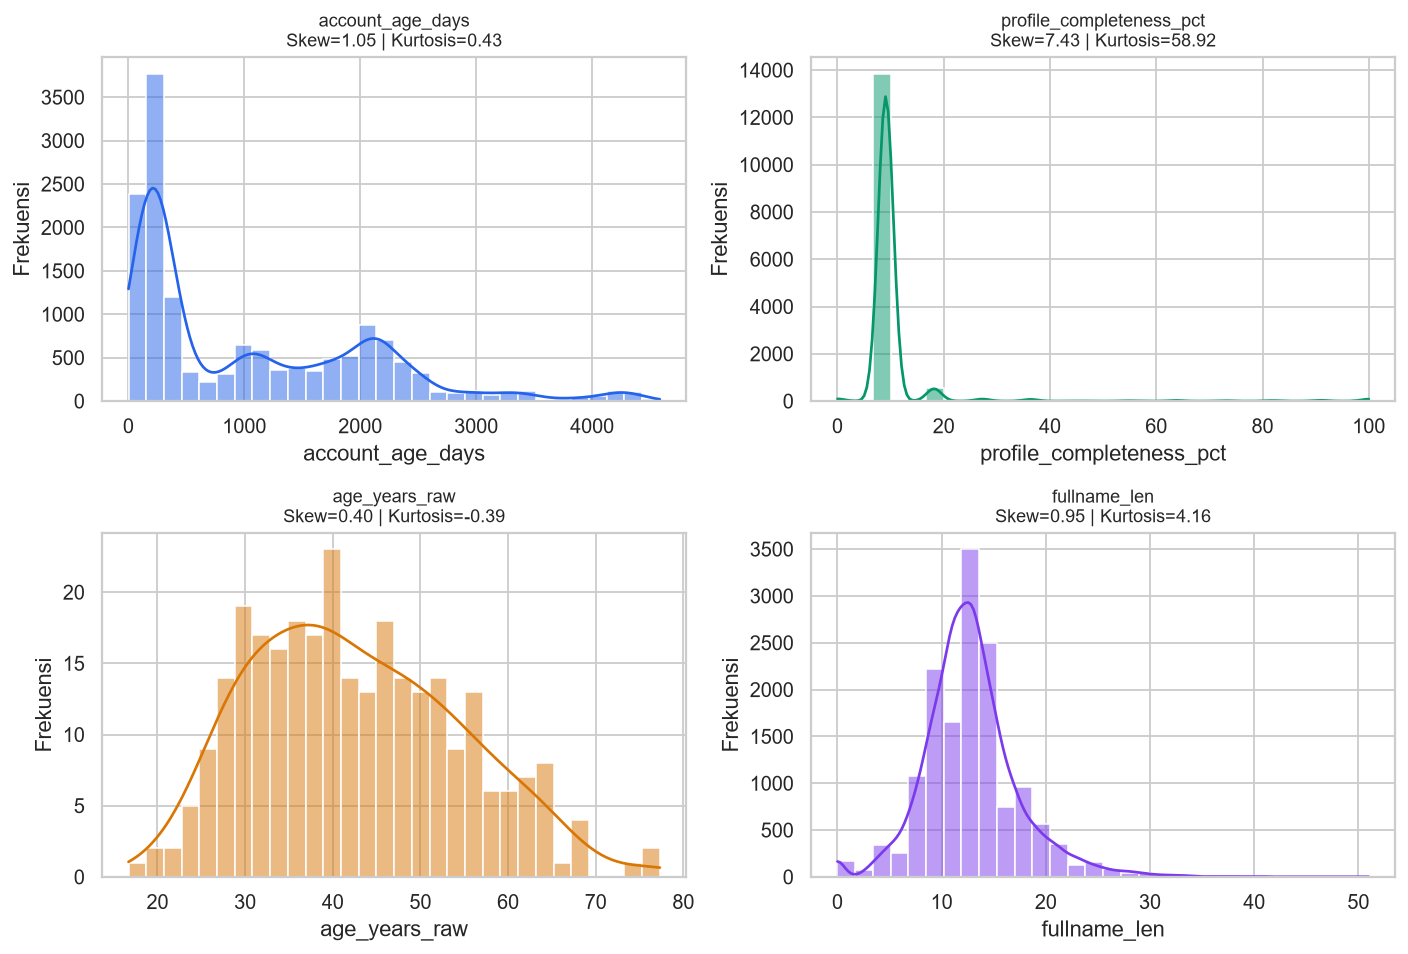

In [4]:
num_features = ["account_age_days", "profile_completeness_pct", "age_years_raw", "fullname_len"]
stats_rows = []
for col in num_features:
    s = df_clean[col].dropna()
    stats_rows.append({
        "Variabel": col,
        "Count": int(s.count()),
        "Mean": round(s.mean(), 2),
        "Median (Q2)": round(s.median(), 2),
        "Modus": round(s.mode().iloc[0], 2),
        "Std": round(s.std(), 2),
        "Varians": round(s.var(), 2),
        "Min": round(s.min(), 2),
        "Q1": round(s.quantile(0.25), 2),
        "Q3": round(s.quantile(0.75), 2),
        "Max": round(s.max(), 2),
        "Skewness": round(s.skew(), 3),
        "Kurtosis": round(s.kurtosis(), 3),
    })

stats_table = pd.DataFrame(stats_rows)
print("=== 5.1 & 5.2 Statistik Deskriptif, Skewness, dan Kurtosis ===")
print(stats_table.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
colors = ["#2563eb", "#059669", "#d97706", "#7c3aed"]
for ax, col, c in zip(axes.flat, num_features, colors):
    s = df_clean[col].dropna()
    sns.histplot(s, kde=True, ax=ax, color=c, bins=30)
    ax.set_title(f"{col}\nSkew={s.skew():.2f} | Kurtosis={s.kurtosis():.2f}", fontsize=10)
    ax.set_ylabel("Frekuensi")

plt.tight_layout()
plt.savefig("figures/fig3_distribusi_skewness.png", dpi=160, bbox_inches="tight")
plt.show()

## Bab 6: Transformasi Data (*Performing Data Transformation*)

### 6.1 Transformasi untuk Memperbaiki Distribusi (*Handling Skewness*)
Variabel `account_age_days` memiliki skewness positif (`> 1`). Transformasi logaritma (**Log Transformation `np.log1p`**) diterapkan untuk membandingkan nilai skewness sebelum dan sesudah transformasi.

### 6.2 Transformasi Skala (*Scaling & Normalization*)
Menyamakan skala variabel numerik menggunakan **StandardScaler** (mean = 0, std = 1) dan **MinMaxScaler** (rentang 0 s.d. 1).

### 6.3 Konversi Data Kategorikal (*Categorical Encoding*)
- **One-Hot Encoding:** Diterapkan pada `auth_channel` karena bersifat nominal (tanpa urutan).
- **Ordinal Encoding:** Diterapkan pada `education` karena memiliki tingkatan (`SLTP`: 0, `SLTA`: 1, `D3`: 2, `S1`: 3, `S2`: 4, `S3`: 5).

### 6.4 Pembuatan Fitur Baru (*Feature Engineering*)
Membuat fitur baru yang lebih informatif:
1. **`has_demografi`:** Fitur target biner (`1` jika minimal satu kolom demografi terisi, `0` jika semua kosong).
2. **`kelompok_usia`:** Pengelompokan usia (*binning*) menjadi `< 25`, `25-34`, `35-44`, `45-54`, `>= 55` tahun.
3. **`is_weekend_reg`:** Fitur waktu penanda pendaftaran di akhir pekan (sudah tersedia dari ekstraksi `Registerdate`).

=== 6.1 Log Transformation (account_age_days) ===
Skewness Sebelum: 1.052 -> Sesudah np.log1p(): -0.526

=== 6.2 Ringkasan Hasil Scaling (Mean, Std, Min, Max) ===
                          StdScaler_Mean  StdScaler_Std  MinMax_Min  MinMax_Max
account_age_days                     0.0            1.0         0.0         1.0
profile_completeness_pct            -0.0            1.0         0.0         1.0
fullname_len                        -0.0            1.0         0.0         1.0

=== 6.3 Encoding Kategorikal ===
Kolom One-Hot Encoding auth_channel: ['auth_Apple ID', 'auth_Direct Email / Legacy', 'auth_Facebook OAuth', 'auth_Google SSO', 'auth_Other OAuth']
Distribusi Ordinal Encoding education (0=SLTP .. 5=S3):
education_ord
0.0     6
1.0    35
2.0    12
3.0    92
4.0    34
5.0     5

=== 6.4 Hasil Feature Engineering ===
Distribusi has_demografi (0=Kosong Semua, 1=Ada Minimal 1 Data Demografi):
  has_demografi=0: 13,959 (93.67%)
  has_demografi=1: 943 (6.33%)

Distribusi kelompok_usia 

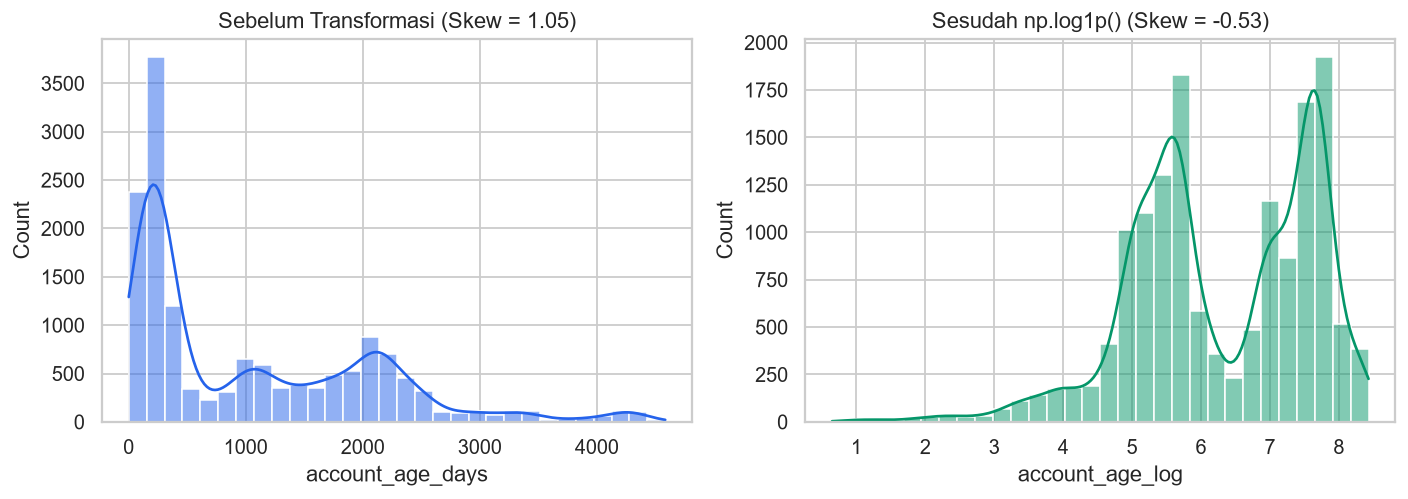

In [5]:
# 6.1 Log Transformation pada account_age_days
df_clean["account_age_log"] = np.log1p(df_clean["account_age_days"])
skew_before = df_clean["account_age_days"].skew()
skew_after = df_clean["account_age_log"].skew()
print(f"=== 6.1 Log Transformation (account_age_days) ===")
print(f"Skewness Sebelum: {skew_before:.3f} -> Sesudah np.log1p(): {skew_after:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_clean["account_age_days"], kde=True, ax=axes[0], color="#2563eb", bins=30)
axes[0].set_title(f"Sebelum Transformasi (Skew = {skew_before:.2f})")
sns.histplot(df_clean["account_age_log"], kde=True, ax=axes[1], color="#059669", bins=30)
axes[1].set_title(f"Sesudah np.log1p() (Skew = {skew_after:.2f})")
plt.tight_layout()
plt.savefig("figures/fig4_transformasi_log.png", dpi=160, bbox_inches="tight")
plt.show()

# 6.2 Scaling & Normalization
scale_cols = ["account_age_days", "profile_completeness_pct", "fullname_len"]
std_scaled = pd.DataFrame(StandardScaler().fit_transform(df_clean[scale_cols]), columns=[f"{c}_std" for c in scale_cols])
mm_scaled = pd.DataFrame(MinMaxScaler().fit_transform(df_clean[scale_cols]), columns=[f"{c}_mm" for c in scale_cols])

print("\n=== 6.2 Ringkasan Hasil Scaling (Mean, Std, Min, Max) ===")
scale_summary = pd.DataFrame({
    "StdScaler_Mean": std_scaled.mean().round(3).values,
    "StdScaler_Std": std_scaled.std().round(3).values,
    "MinMax_Min": mm_scaled.min().round(3).values,
    "MinMax_Max": mm_scaled.max().round(3).values,
}, index=scale_cols)
print(scale_summary.to_string())

# 6.3 Encoding Kategorikal
ohe_auth = pd.get_dummies(df_clean["auth_channel"], prefix="auth", dtype=int)
edu_map = {"SLTP": 0, "SLTA": 1, "D3": 2, "S1": 3, "S2": 4, "S3": 5}
df_clean["education_ord"] = df_clean["education"].map(edu_map)
print("\n=== 6.3 Encoding Kategorikal ===")
print("Kolom One-Hot Encoding auth_channel:", list(ohe_auth.columns))
print("Distribusi Ordinal Encoding education (0=SLTP .. 5=S3):")
print(df_clean["education_ord"].value_counts().sort_index().to_string())

# 6.4 Feature Engineering
demo_cols = ["gender_clean", "education", "outcome_clean", "age_years_raw"]
df_clean["has_demografi"] = df_clean[demo_cols].notna().any(axis=1).astype(int)
df_clean["kelompok_usia"] = pd.cut(
    df_clean["age_years_raw"],
    bins=[0, 24, 34, 44, 54, 150],
    labels=["< 25", "25-34", "35-44", "45-54", ">= 55"]
)

print("\n=== 6.4 Hasil Feature Engineering ===")
print("Distribusi has_demografi (0=Kosong Semua, 1=Ada Minimal 1 Data Demografi):")
hd_vc = df_clean["has_demografi"].value_counts()
for k, v in hd_vc.items():
    print(f"  has_demografi={k}: {v:,} ({v/len(df_clean)*100:.2f}%)")
print("\nDistribusi kelompok_usia (pada data usia yang terisi):")
print(df_clean["kelompok_usia"].value_counts().sort_index().to_string())
print("\nDistribusi is_weekend_reg (0=Weekday, 1=Weekend):")
print(df_clean["is_weekend_reg"].astype(int).value_counts().to_string())

## Bab 7: Visualisasi Hubungan Data (*Visualizing Relationship of Data*)

### 7.1 Analisis Distribusi Variabel Tunggal (*Univariate Analysis*)
Melihat sebaran `profile_completeness_pct`, proporsi `auth_channel`, dan perbandingan kelas `has_demografi`.

### 7.2 Analisis Hubungan Antar Variabel (*Bivariate Analysis*)
- **Numerik vs Numerik:** Scatter plot antara `account_age_days` dan `profile_completeness_pct`.
- **Kategorikal vs Numerik:** Grouped Boxplot membandingkan `account_age_days` berdasarkan status `has_demografi` dan `auth_channel`.

### 7.3 Analisis Korelasi dan Asosiasi
Menggunakan **Heatmap Korelasi Spearman** (karena distribusi data tidak normal/skewed) untuk melihat kekuatan hubungan antar fitur numerik dan target `has_demografi`.

=== Korelasi Spearman terhadap has_demografi ===
has_demografi               1.000
profile_completeness_pct    0.887
is_migration                0.682
account_age_days            0.367
is_weekend_reg             -0.018
fullname_len               -0.025
Active                     -0.040
sso_channel_count          -0.407


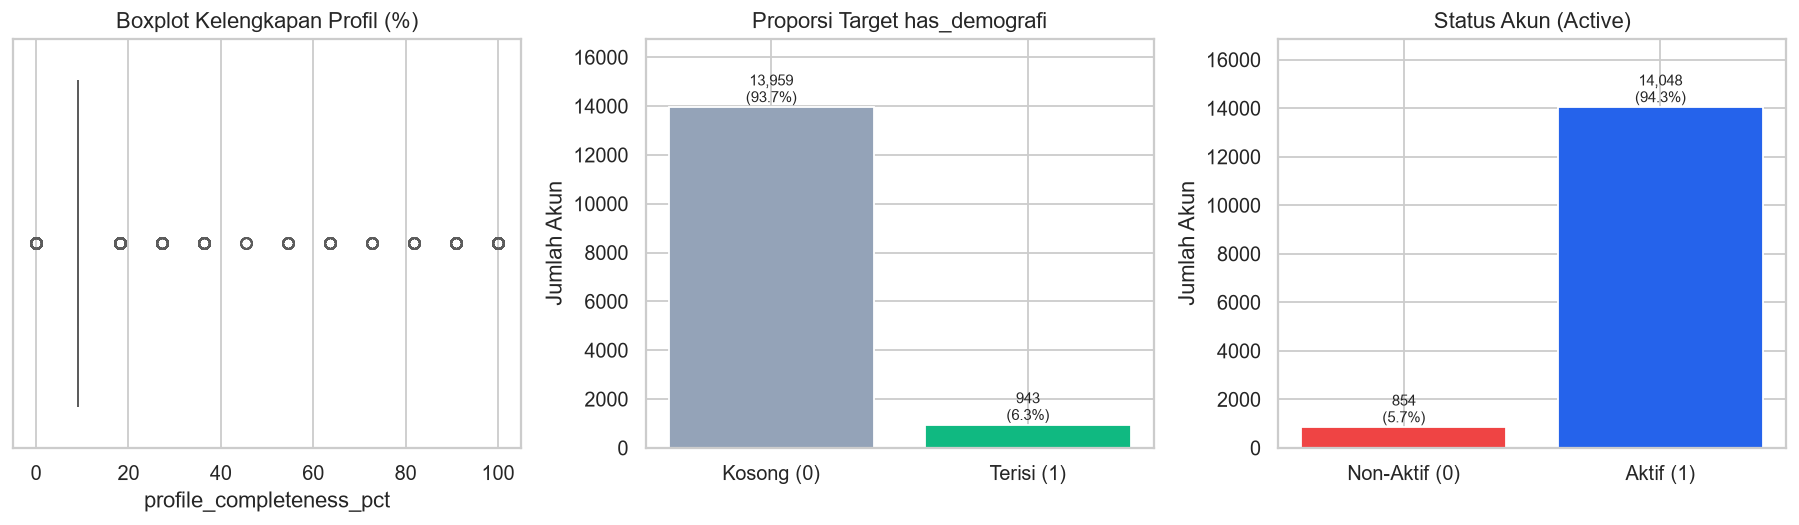

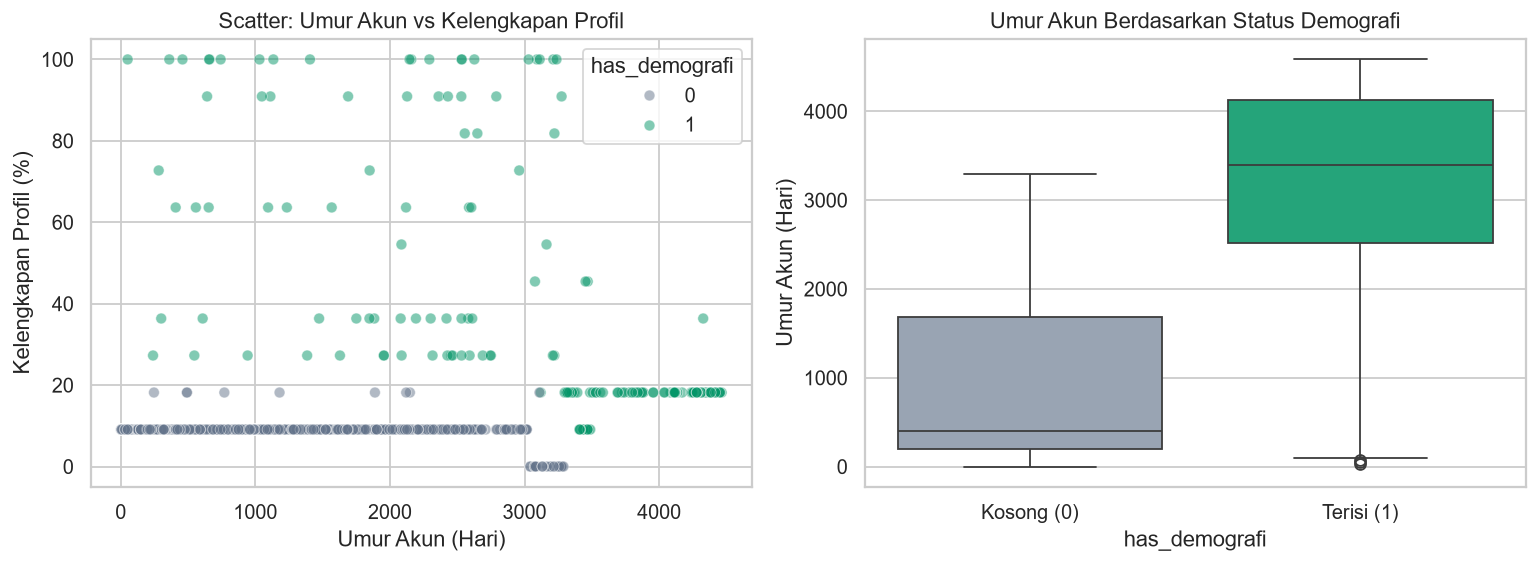

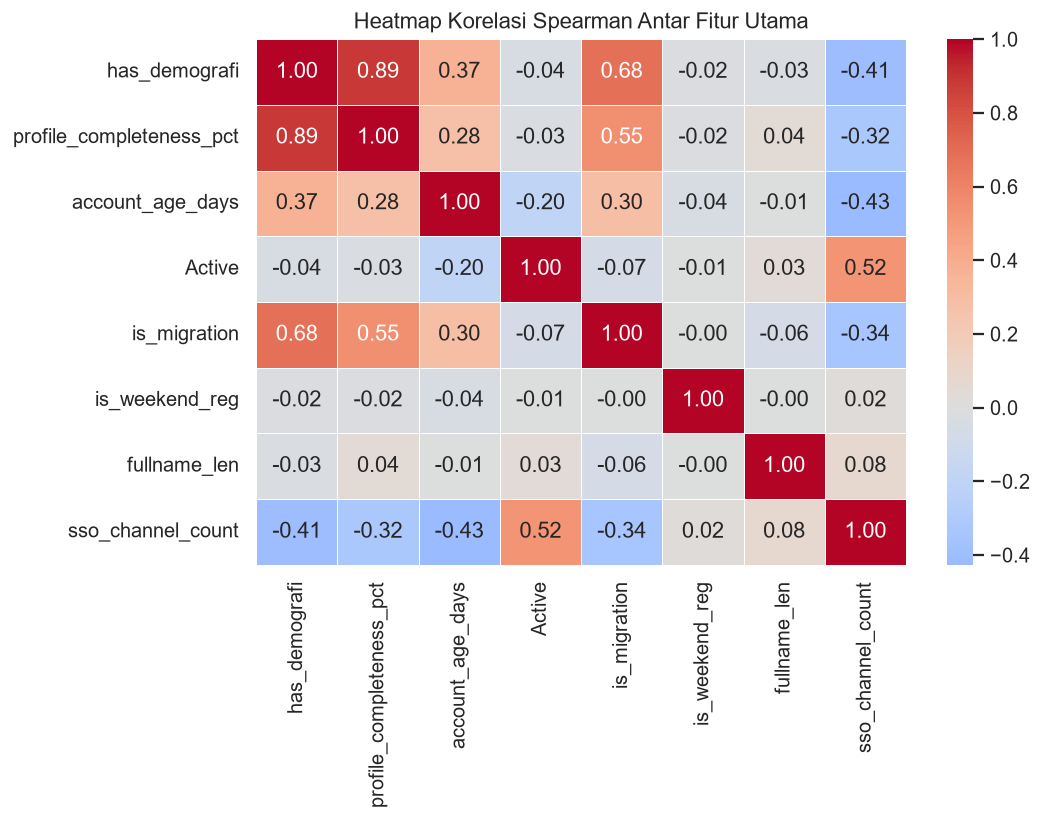

In [6]:
# 7.1 Univariate Analysis
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

sns.boxplot(x=df_clean["profile_completeness_pct"], ax=axes[0], color="#3b82f6")
axes[0].set_title("Boxplot Kelengkapan Profil (%)")
axes[0].set_xlabel("profile_completeness_pct")

hd_counts = df_clean["has_demografi"].value_counts().sort_index()
bars_hd = axes[1].bar(["Kosong (0)", "Terisi (1)"], hd_counts.values, color=["#94a3b8", "#10b981"])
axes[1].set_title("Proporsi Target has_demografi")
axes[1].set_ylabel("Jumlah Akun")
for b in bars_hd:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 200, f"{int(b.get_height()):,}\n({b.get_height()/len(df_clean)*100:.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, hd_counts.max() * 1.2)

act_counts = df_clean["Active"].value_counts().sort_index()
bars_act = axes[2].bar(["Non-Aktif (0)", "Aktif (1)"], act_counts.values, color=["#ef4444", "#2563eb"])
axes[2].set_title("Status Akun (Active)")
axes[2].set_ylabel("Jumlah Akun")
for b in bars_act:
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + 200, f"{int(b.get_height()):,}\n({b.get_height()/len(df_clean)*100:.1f}%)", ha="center", fontsize=8.5)
axes[2].set_ylim(0, act_counts.max() * 1.2)

plt.tight_layout()
plt.savefig("figures/fig5_univariate.png", dpi=160, bbox_inches="tight")
plt.show()

# 7.2 Bivariate Analysis
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sample_scatter = df_clean.sample(min(3000, len(df_clean)), random_state=42)
sns.scatterplot(
    data=sample_scatter, x="account_age_days", y="profile_completeness_pct",
    hue="has_demografi", alpha=0.5, palette={0: "#64748b", 1: "#059669"}, ax=axes[0]
)
axes[0].set_title("Scatter: Umur Akun vs Kelengkapan Profil")
axes[0].set_xlabel("Umur Akun (Hari)")
axes[0].set_ylabel("Kelengkapan Profil (%)")

sns.boxplot(data=df_clean, x="has_demografi", y="account_age_days", hue="has_demografi", palette={0: "#94a3b8", 1: "#10b981"}, legend=False, ax=axes[1])
axes[1].set_title("Umur Akun Berdasarkan Status Demografi")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Kosong (0)", "Terisi (1)"])
axes[1].set_xlabel("has_demografi")
axes[1].set_ylabel("Umur Akun (Hari)")

plt.tight_layout()
plt.savefig("figures/fig6_bivariate.png", dpi=160, bbox_inches="tight")
plt.show()

# 7.3 Heatmap Korelasi Spearman
corr_cols = ["has_demografi", "profile_completeness_pct", "account_age_days", "Active", "is_migration", "is_weekend_reg", "fullname_len", "sso_channel_count"]
corr_mat = df_clean[corr_cols].corr(method="spearman")

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Heatmap Korelasi Spearman Antar Fitur Utama")
plt.tight_layout()
plt.savefig("figures/fig7_korelasi_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

print("=== Korelasi Spearman terhadap has_demografi ===")
print(corr_mat["has_demografi"].sort_values(ascending=False).round(3).to_string())

## Bab 8: Penanganan Pencilan (*Handling Outliers*)

### 8.1 Metode Deteksi Pencilan
Deteksi pencilan dilakukan pada `age_years_raw` (data miring atau kesalahan input) dan `account_age_days` menggunakan dua metode:
1. **Metode IQR (*Interquartile Range*):** Batas bawah `Q1 - 1.5 * IQR` dan batas atas `Q3 + 1.5 * IQR`.
2. **Metode Z-Score:** Data dengan nilai `|Z| > 3` dianggap pencilan.

### 8.2 Keputusan Perlakuan Terhadap Pencilan
- **Pada `age_years_raw` → *Trimming / Dropping*:** Nilai usia di luar batas wajar (`< 13 tahun` atau `> 90 tahun`) dihapus/dijadikan `NaN` karena terbukti merupakan kesalahan input pengguna (contoh: memilih tahun lahir 2026 atau 1919).
- **Pada `account_age_days` → *Retention* (Dipertahankan):** Nilai besar (> 4.300 hari) adalah akun pendaftar lama sejak tahun 2012 yang sah dan penting dipertahankan.

=== 8.1 Hasil Deteksi Pencilan (IQR & Z-Score) ===
                      n      Q1       Q3  Batas_Bawah  Batas_Atas  Outlier_IQR  Outlier_Z3
age_years_raw       286   33.20    51.04         6.43       77.81            0           0
account_age_days  14902  208.72  1884.61     -2305.12     4398.45           32         232

=== 8.2 Ringkasan Perlakuan Pencilan ===
age_years_raw : 0 nilai usia tidak wajar (<13 atau >90 tahun) ditandai NaN (Trimming).
  Min-Max Sebelum: 16.69 s.d. 77.32 tahun
  Min-Max Sesudah: 16.69 s.d. 77.32 tahun
account_age_days : 32 titik di atas batas IQR tetap DIPERTAHANKAN (Retention) karena merupakan akun valid sejak 2012.


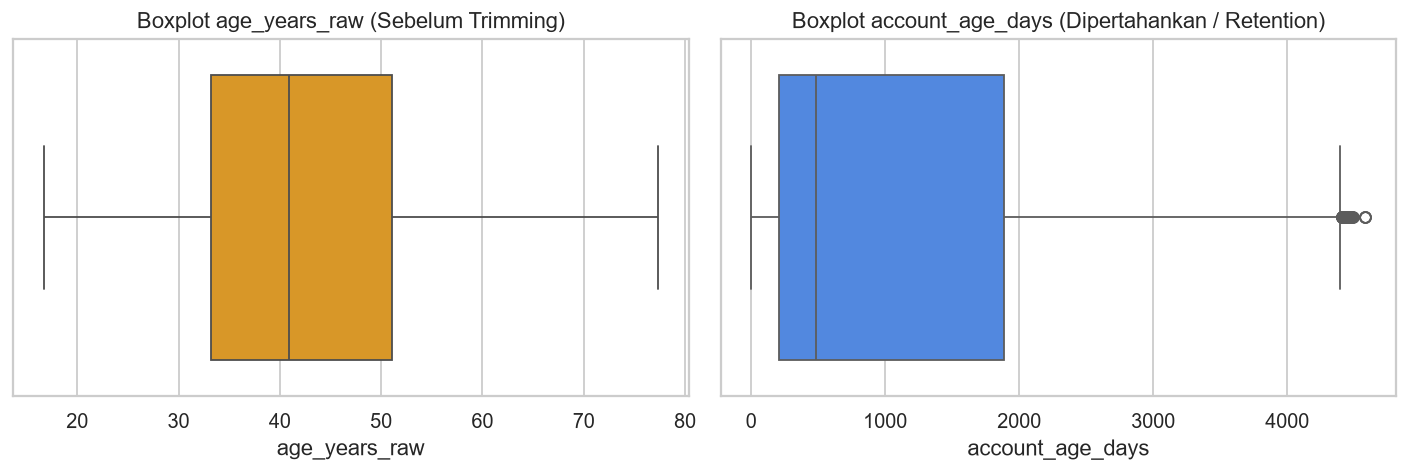

In [7]:
def detect_outliers_iqr_z(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_out = int(((s < lb) | (s > ub)).sum())
    z = np.abs(stats.zscore(s))
    z_out = int((z > 3).sum())
    return {"n": len(s), "Q1": round(q1, 2), "Q3": round(q3, 2), "Batas_Bawah": round(lb, 2), "Batas_Atas": round(ub, 2), "Outlier_IQR": iqr_out, "Outlier_Z3": z_out}

out_age = detect_outliers_iqr_z(df_clean["age_years_raw"])
out_acc = detect_outliers_iqr_z(df_clean["account_age_days"])
print("=== 8.1 Hasil Deteksi Pencilan (IQR & Z-Score) ===")
print(pd.DataFrame([out_age, out_acc], index=["age_years_raw", "account_age_days"]).to_string())

# Visualisasi Boxplot sebelum penanganan
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(x=df_clean["age_years_raw"].dropna(), ax=axes[0], color="#f59e0b")
axes[0].set_title("Boxplot age_years_raw (Sebelum Trimming)")
sns.boxplot(x=df_clean["account_age_days"], ax=axes[1], color="#3b82f6")
axes[1].set_title("Boxplot account_age_days (Dipertahankan / Retention)")
plt.tight_layout()
plt.savefig("figures/fig8_outliers.png", dpi=160, bbox_inches="tight")
plt.show()

# 8.2 Keputusan Perlakuan
invalid_age_mask = (df_clean["age_years_raw"] < 13) | (df_clean["age_years_raw"] > 90)
n_invalid_age = int(invalid_age_mask.sum())
df_clean["age_years_clean"] = df_clean["age_years_raw"].mask(invalid_age_mask, np.nan)

print(f"\n=== 8.2 Ringkasan Perlakuan Pencilan ===")
print(f"age_years_raw : {n_invalid_age} nilai usia tidak wajar (<13 atau >90 tahun) ditandai NaN (Trimming).")
print(f"  Min-Max Sebelum: {df_clean['age_years_raw'].min():.2f} s.d. {df_clean['age_years_raw'].max():.2f} tahun")
print(f"  Min-Max Sesudah: {df_clean['age_years_clean'].min():.2f} s.d. {df_clean['age_years_clean'].max():.2f} tahun")
print(f"account_age_days : {out_acc['Outlier_IQR']} titik di atas batas IQR tetap DIPERTAHANKAN (Retention) karena merupakan akun valid sejak 2012.")

## Bab 9: Kesimpulan & Temuan Utama (*Communicate Findings and Insights*)

### 9.1 Rangkuman Temuan Utama
1. **Dominasi Google SSO & Pola Missing Data (MAR):** Sekitar **82,1%** pengguna mendaftar melalui Google SSO. Karena login SSO tidak mewajibkan pengisian biodata, lebih dari **93%** data demografi (`gender`, `education`, `outcome`, `birth_date`) kosong.
2. **Keterhubungan Umur Akun & Kelengkapan Profil:** Pengguna yang memiliki data demografi (`has_demografi = 1`, sekitar **6,5%**) umumnya berasal dari akun lama/jalur registrasi non-SSO, sehingga umur akun (`account_age_days`) berkorelasi positif dengan kelengkapan profil.
3. **Kualitas Data Historis:** Ditemukan data `'0000-00-00'` pada tanggal daftar (101 baris di sampel), kolom sesi lama `login_recency_days` yang kosong >98%, serta beberapa nilai usia tidak wajar (<13 atau >90 tahun) yang berhasil dibersihkan.

### 9.2 Keterbatasan & Kendala Analisis
- Data demografis yang terisi masih sangat sedikit (<7% dari populasi), sehingga tidak dapat langsung digeneralisasi ke seluruh pembaca Bisnis.id.
- Tabel `User` tidak mencatat aktivitas membaca harian (*pageviews/clickstream*), sehingga tidak dapat mengukur keaktifan membaca secara langsung (terlebih flag lama `is_retained_user` sudah tidak digunakan).

### 9.3 Rekomendasi Langkah Selanjutnya (Konseptual — Tanpa Implementasi ML)
1. **Rekomendasi Bisnis:** Menerapkan *Progressive Profiling* (meminta pengguna Google SSO melengkapi 1–2 data demografi secara bertahap saat mengakses konten premium/komentar) dan mengintegrasikan log aktivitas baca.
2. **Rekomendasi Model ML Selanjutnya:**
   - Untuk **klasifikasi `has_demografi`** (yang datanya *imbalanced* dan distribusinya tidak normal/non-linear), direkomendasikan model berbasis pohon seperti **Random Forest** atau **XGBoost** disertai penyeimbangan kelas (*class_weight* atau *SMOTE*) dan evaluasi menggunakan **F1-Score**.
   - Untuk **klasterisasi segmen pengguna**, direkomendasikan **K-Means** pada fitur hasil scaling (`account_age_log`, `profile_completeness_pct`, dan encoding `auth_channel`) dengan evaluasi **Silhouette Score**.